# 多模态RAG-技术方案1

# 获取多模态数据

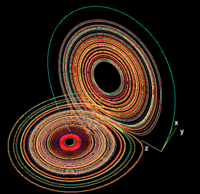

In [5]:
from PIL import Image
from IPython.display import display

# 加载图片（洛伦兹系统：大气对流模型）
image = Image.open("clip_resource/Lorenz_Ro28-200px.png").convert('RGB')
display(image)

In [6]:
# 播放音频

import IPython.display as ipd
ipd.Audio("clip_resource/audio.mp3")

数据类型: float32
数组形状: (412638,)
采样率: 16000 Hz
时长: 25.789875 秒
音频数据： [ 0.00200962  0.00379075  0.00347673 ... -0.00112898 -0.00128486
  0.        ]


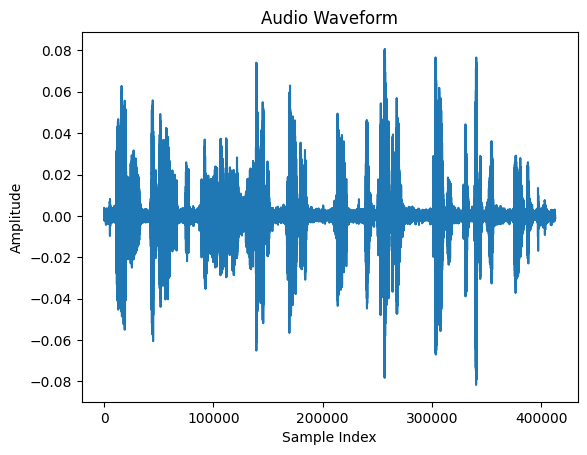

In [7]:
# 加载音频

import librosa
import matplotlib.pyplot as plt

# 1. 读取MP3文件，直接返回NumPy浮点型数组和采样率
# 注意：librosa默认会将音频重采样到22050 Hz，可通过sr设置采样率
audio_array, sample_rate = librosa.load("clip_resource/audio.mp3", sr=16000, mono=False)

# 2. 获取音频属性
print(f"数据类型: {audio_array.dtype}")  # 通常是float32
print(f"数组形状: {audio_array.shape}")  # (声道数, 采样点数) 或 (采样点数,)
print(f"采样率: {sample_rate} Hz")
duration = librosa.get_duration(y=audio_array, sr=sample_rate, S=None)
print(f"时长: {duration} 秒")
print("音频数据：", audio_array)

# 画图
plt.plot(audio_array)
plt.title("Audio Waveform")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.show()

In [8]:
# 加载文本
text_data = open("clip_resource/Wiki.txt").readlines()[0]
text_data = text_data[:300]
print(text_data)

All Quiet on the Western Front (German: Im Westen nichts Neues, lit. 'In the West, nothing new') is a semi-autobiographical novel by Erich Maria Remarque, a German veteran of World War I. The book describes the German soldiers' extreme physical and mental trauma during the war as well as the detachm


# 用ASR把音频转文字

In [9]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration
from datasets import load_dataset

# load model and processor
processor = WhisperProcessor.from_pretrained("openai/whisper-base")
model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-base")
model.config.forced_decoder_ids = None

input_features = processor(audio_array, sampling_rate=sample_rate, return_tensors="pt").input_features 

# generate token ids
predicted_ids = model.generate(input_features)
# decode token ids to text
audio_transcription = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]
audio_transcription

Due to a bug fix in https://github.com/huggingface/transformers/pull/28687 transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English.This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`.
Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.43.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token.As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


" I recorded a more complex audio file, but I'm going to re-record with a simpler one because it was surprisingly difficult. My favorite harbist is Trulo O'Carlin. Torlo? No. Tor- uh, whatever."

# 输入

In [12]:
# query = "who is my favorite harpist?"
query = '我最喜欢的竖琴演奏家是谁？'

# 模态数据嵌入-> Embedding

In [21]:
## 对音频编码
# from transformers import ClapProcessor, ClapModel
# clap_model = ClapModel.from_pretrained("laion/clap-htsat-fused")
# processor = ClapProcessor.from_pretrained("laion/clap-htsat-fused")

# inputs = processor(audios=audio_array, return_tensors="pt")
# audio_embeddings = clap_model.get_audio_features(**inputs)

In [14]:
from transformers import CLIPProcessor, CLIPModel

# Load the model and processor
# 实现图片+文字的编码，这两个编码是语义对齐了的
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Encode the image
inputs = processor(images=image, return_tensors="pt")
image_embeddings = model.get_image_features(**inputs)

# Encode the text
inputs = processor(text=[query, audio_transcription, text_data], return_tensors="pt", padding=True)
text_embeddings = model.get_text_features(**inputs)

# Print or use the embeddings
print("Image Embeddings:", image_embeddings)
print("Text Embeddings:", text_embeddings)

Image Embeddings: tensor([[-5.2262e-02, -3.3041e-01,  2.2335e-01, -7.3058e-02, -1.5052e-01,
         -5.1145e-02, -9.7562e-02,  3.7208e-01,  7.5285e-01,  3.3993e-02,
          3.5383e-01,  4.1364e-01,  3.0276e-01,  5.1187e-02, -2.5875e-01,
          4.0375e-01,  2.0690e-01, -7.6874e-02, -3.2173e-01,  3.3232e-01,
         -9.4834e-02, -3.5299e-01, -1.7429e-01,  1.8234e-01,  1.2910e-01,
          1.5670e-01,  6.4602e-02, -5.1670e-01, -2.8095e-01, -4.6208e-01,
          2.6887e-01,  1.2401e-01,  2.3723e-01,  2.5057e-01, -2.1883e-01,
         -2.1862e-01,  4.7316e-01,  9.7232e-02, -2.2566e-01, -1.2843e+00,
         -1.5478e-01,  1.4792e-01,  1.7079e-01, -2.7122e-01,  7.0894e-02,
         -5.7417e-01, -1.4849e-01,  5.0876e-01, -3.3328e-01,  5.5560e-02,
         -2.1642e-01,  1.2332e-01, -5.5301e-02,  1.2325e-02, -2.0469e-01,
         -1.5992e-01, -3.8839e-01,  4.2273e-02, -1.3538e-01,  1.3254e-01,
          6.2206e-01, -2.0923e-01, -1.4633e-01, -1.7798e-01, -2.1673e-01,
         -3.6287e-01

In [15]:
image_embeddings.shape, text_embeddings.shape

(torch.Size([1, 512]), torch.Size([3, 512]))

# 计算不同模态间的cosine相似度

In [32]:
from torch.nn.functional import cosine_similarity

image_embedding = image_embeddings[0]
query_embedding = text_embeddings[0]
audio_embedding = text_embeddings[1]
text_embedding = text_embeddings[2]

# Calculate cosine similarity
cos_sim_query_image = cosine_similarity(query_embedding.unsqueeze(0), image_embedding.unsqueeze(0)).item()
cos_sim_query_audio = cosine_similarity(query_embedding.unsqueeze(0), audio_embedding.unsqueeze(0)).item()
cos_sim_query_text = cosine_similarity(query_embedding.unsqueeze(0), text_embedding.unsqueeze(0)).item()

# Print the results
print(f"Cosine Similarity between query and image embedding: {cos_sim_query_image:.4f}")
print(f"Cosine Similarity between query and audio embedding: {cos_sim_query_audio:.4f}")
print(f"Cosine Similarity between query and text embedding: {cos_sim_query_text:.4f}")

Cosine Similarity between query and image embedding: 0.1928
Cosine Similarity between query and audio embedding: 0.7653
Cosine Similarity between query and text embedding: 0.6411


# 多模态增强生成

In [33]:
# !pip install google-genai 
import os
from google import genai
from google.genai import types
from dotenv import load_dotenv

# 加载环境变量
load_dotenv()


google_client = genai.Client(
    api_key=os.getenv("API_KEY"),
    http_options={
        "base_url": "https://api.zhizengzeng.com/google"
    },
)

In [35]:
similarities = [cos_sim_query_image, cos_sim_query_audio, cos_sim_query_text]

if max(similarities) == cos_sim_query_image:
    # 图像相似度最高，用图像来增强生成
    result = google_client.models.generate_content(
        model="gemini-2.5-flash",
        contents=[query, image]
    )

elif max(similarities) == cos_sim_query_audio:
    # 音频相似度最高，用转写后的ASR文本来增强生成
    result = google_client.models.generate_content(
        model="gemini-2.5-flash",
        contents=[query, 'audio transcript: ' + audio_transcription]
    )

elif max(similarities) == cos_sim_query_text:
    # 文本相似度最高，用文本来增强生成
    result = google_client.models.generate_content(
        model="gemini-2.5-flash",
        contents=[query, text_data]
    )

print(result.text)

根据您的音频，您似乎想说您最喜欢的竖琴演奏家是 **Turlough O'Carolan (图洛赫·奥卡罗兰)**。

您在音频中说的是 "Trulo O'Carlin" 或 "Torlo O'Carlin"，这与爱尔兰著名的盲人竖琴演奏家兼作曲家 Turlough O'Carolan 的名字非常接近。他是爱尔兰历史上最著名的竖琴演奏家之一。
